# Noise Sensitivity — Synthetic Data Generation (25-warming-event regime)

**Goal:** generate synthetic `Melcher25` bistable time series under a single **fixed** dynamics configuration, then add **proxy/observation noise** that varies systematically in both **amplitude** (low/medium/high) and **spectral color** (white/pink/red) — as inputs for a later, separate notebook that will run Ammonyte's detection methods on them and measure how detection ability degrades with noise.


**Why fixed dynamics, decoupled from NGRIP:** this is a general robustness characterization of noise sensitivity, not a claim about NGRIP transferability (that's what `NGRIP_Parameter_Search_Melcher25.ipynb` / scenario 1 is for). Isolating noise as the only varying factor means any change in detection performance across conditions can be attributed to noise alone, not to a shifting dynamical regime.

**Parameter choices** (cross-checked against Melcher et al. 2025, *Clim. Past* 21, 115-132, Sec. 2.3.5):
- `sigma = 0.5` — process noise. The paper gives no formal upper bound (only a qualitative note that too-high sigma causes random-walk-like behavior); 0.5 sits just above the original calibration grid's explored range ([0.15, 0.4]) while remaining clearly bistable (verified below).
- `gamma = 1.5` — forcing; mid-range of the paper's actual constraint `[0.6, 3.0]`, and the package default.
- `alpha = -0.5` — AABW coupling; mid-range of the paper's constraint `[-1.0, 0.0]`. Deliberately *not* the package default (`0.0`), since that sits exactly on the paper's instability boundary (alpha > 0 diverges) — using a boundary value here would confound alpha's own instability with the noise effects we're trying to isolate.

**Structure**
- Section 1 — Fixed dynamics configuration
- Section 2 — Colored-noise generation utility
- Section 3 — Build the noise grid (color x amplitude x seeds) and generate datasets
- Section 4 — Sanity-check visualization
- Section 5 — Save datasets for later Ammonyte analysis

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, json, glob


from climatecritters.model_critters.melcher25 import Melcher25, classify_bistable_states
from climatecritters.utils.noise import from_param

---
## Section 1 — Fixed Dynamics Configuration

`sigma`, `gamma`, `alpha` are fixed for the entire notebook (see rationale above). `b0`, `q0`, `q1`, `tau` stay at their NGRIP-calibrated defaults. The time span/resolution match NGRIP's glacial-period coverage, consistent with scenario 1.

In [4]:
SIGMA = 0.5   # process noise (see rationale above)
GAMMA = 1.5   # forcing (paper default, mid-range of [0.6, 3.0])
ALPHA = -0.5  # AABW coupling (mid-range of [-1.0, 0.0], avoids the alpha=0 instability boundary)

T_SPAN = (0, 120)   # kyr, matches NGRIP glacial-period coverage (~11-121 ka BP)
DT     = 0.02
Y0     = [1.0, 0.0]

OUT_DIR = "/Users/maryamniati/Documents/Syntheticdata/noise_sensitivity_data"
os.makedirs(OUT_DIR, exist_ok=True)


def transition_times_from_states(time, states):
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


# Sanity check: confirm the fixed configuration is well-behaved before building the full grid
_check_model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
_check_output = _check_model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                                        kwargs={'random_seed': 0, 'si': DT})
_check_db = np.asarray(_check_output.state_variables['db'])
_check_states = np.asarray(_check_output.diagnostic_variables['states'])
assert np.all(np.isfinite(_check_db)), "Fixed configuration produced non-finite values"
print(f"Fixed config sanity check: {len(_check_db)} points, finite=True, "
      f"{int(np.sum(np.diff(_check_states) != 0))} transitions, "
      f"thresholds=({_check_model.stadial_threshold:.3f}, {_check_model.interstadial_threshold:.3f})")

Fixed config sanity check: 6001 points, finite=True, 47 transitions, thresholds=(1.023, 1.375)


---
## Section 2 — Colored-Noise Generation

`climatecritters.utils.noise.from_param` wraps `pyleoclim.SurrogateSeries` and supports colored noise (`method='CN'`) parameterized by spectral exponent `beta`: `beta=0` is white, `beta=1` is pink (1/f), `beta=2` is red. Its output comes out already at unit standard deviation regardless of `beta` (verified empirically), so amplitude is controlled separately by explicit rescaling here — that keeps *color* and *amplitude* as independent, cleanly separable axes of the sensitivity grid.

Amplitude levels (target noise std) are anchored to the same scale used in scenario 1's joint search (`sigma_noise` was searched over `[0, 0.08]`, capped there because amplitudes approaching the stadial/interstadial threshold gap, ~0.33-0.38, make the threshold classifier chatter).

In [19]:
NOISE_COLORS = {'white': 0.0, 'pink': 1.0, 'red': 2.0}       # CN spectral exponent beta

# SNR levels: sigma_noise = gap / k, SNR_dB = 20*log10(k) (gap=0.3519 at fixed alpha=-0.5)
NOISE_LEVELS = {'snr4': 0.0880, 'snr3': 0.1173, 'snr2': 0.1760}
N_SEEDS = 20                                                   # realizations per (color, level) condition


def generate_colored_noise(beta, amplitude, length, seed):
    """Zero-mean noise with a target spectral color (beta) and amplitude (std)."""
    surr = from_param(method='CN', noise_param=[beta], length=length, number=1, seed=seed)
    return surr.series_list[0].standardize(scale=amplitude).value

def simulate_condition(beta, amplitude, base_seed, noise_seed):
    """Simulate one realization of the fixed dynamics, then add colored observation noise.

    ``base_seed`` drives the SDE's own process noise (the underlying trajectory);
    ``noise_seed`` drives the added observation noise only. Reusing the same
    ``base_seed`` across different (color, level) conditions means the *same*
    ground-truth trajectory is compared under different noise conditions — so any
    difference in detected transitions is attributable to the noise alone.
    """
    model = Melcher25(sigma=SIGMA, gamma=GAMMA, alpha=ALPHA)
    output = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                              kwargs={'random_seed': base_seed, 'si': DT})

    time = output.time
    db_true = np.asarray(output.state_variables['db']).copy()
    true_states = np.asarray(output.diagnostic_variables['states']).copy()

    noise = generate_colored_noise(beta, amplitude, length=len(db_true), seed=noise_seed)
    output.add_noise('db', noise)
    db_noisy = np.asarray(output.state_variables['db'])

    observed_states = classify_bistable_states(db_noisy, alpha=ALPHA)
    return time, db_true, db_noisy, true_states, observed_states

In [20]:
surr = from_param(method='CN', noise_param=[1.0], length=6001, number=1, seed=0)
print(type(surr))
print(type(surr.series_list[0]))

<class 'pyleoclim.core.surrogateseries.SurrogateSeries'>
<class 'pyleoclim.core.series.Series'>


---
## Section 3 — Build the Noise Grid

3 colors x 3 amplitude levels x 20 seeds = 180 realizations. For a given seed, the ground-truth trajectory (`base_seed`) is identical across all 9 (color, level) conditions — only the added noise differs.

In [21]:
color_items = list(NOISE_COLORS.items())
level_items = list(NOISE_LEVELS.items())

summary_rows = []
grid_data = {}   # (color_name, level_name) -> dict of stacked arrays across seeds

for ci, (color_name, beta) in enumerate(color_items):
    for li, (level_name, amplitude) in enumerate(level_items):
        time_ref = None
        db_true_stack, db_noisy_stack = [], []
        state_true_stack, state_observed_stack = [], []

        for s in range(N_SEEDS):
            base_seed = s
            noise_seed = 1000 * (ci * len(level_items) + li) + s

            time, db_true, db_noisy, true_states, obs_states = simulate_condition(
                beta, amplitude, base_seed=base_seed, noise_seed=noise_seed)

            if time_ref is None:
                time_ref = time

            db_true_stack.append(db_true)
            db_noisy_stack.append(db_noisy)
            state_true_stack.append(true_states)
            state_observed_stack.append(obs_states)

            true_trans = transition_times_from_states(time, true_states)
            obs_trans = transition_times_from_states(time, obs_states)
            summary_rows.append(dict(
                color=color_name, level=level_name, amplitude=amplitude, seed=s,
                n_true_transitions=len(true_trans),
                n_observed_transitions=len(obs_trans),
            ))

        grid_data[(color_name, level_name)] = dict(
            time=time_ref,
            db_true=np.vstack(db_true_stack),
            db_noisy=np.vstack(db_noisy_stack),
            state_true=np.vstack(state_true_stack),
            state_observed=np.vstack(state_observed_stack),
        )
        print(f"Done: color={color_name:5s} level={level_name:6s} (amplitude={amplitude})")

summary_df = pd.DataFrame(summary_rows)
print(f"\nCompleted {len(summary_df)} realizations across {len(grid_data)} conditions")

Done: color=white level=snr4   (amplitude=0.088)
Done: color=white level=snr3   (amplitude=0.1173)
Done: color=white level=snr2   (amplitude=0.176)
Done: color=pink  level=snr4   (amplitude=0.088)
Done: color=pink  level=snr3   (amplitude=0.1173)
Done: color=pink  level=snr2   (amplitude=0.176)
Done: color=red   level=snr4   (amplitude=0.088)
Done: color=red   level=snr3   (amplitude=0.1173)
Done: color=red   level=snr2   (amplitude=0.176)

Completed 180 realizations across 9 conditions


In [22]:
# Quick numeric look: does the observed transition count drift from the true count as noise increases?
# (Not an Ammonyte metric — just an early data-quality signal to catch runaway chatter before saving.)
summary_df.groupby(['color', 'level'])[['n_true_transitions', 'n_observed_transitions']].mean()

n_true_transitions  n_observed_transitions
color level                                            
pink  snr2                44.85                   76.40
      snr3                44.85                   56.15
      snr4                44.85                   48.90
red   snr2                44.85                   48.95
      snr3                44.85                   46.75
      snr4                44.85                   45.35
white snr2                44.85                  177.55
      snr3                44.85                   80.80
      snr4                44.85                   58.50

---
## Section 4 — Qualitative Visual Check 

One example realization (seed 0) per noise color at the medium amplitude level, to visually confirm the colors look distinct and that the classifier isn't obviously chattering.

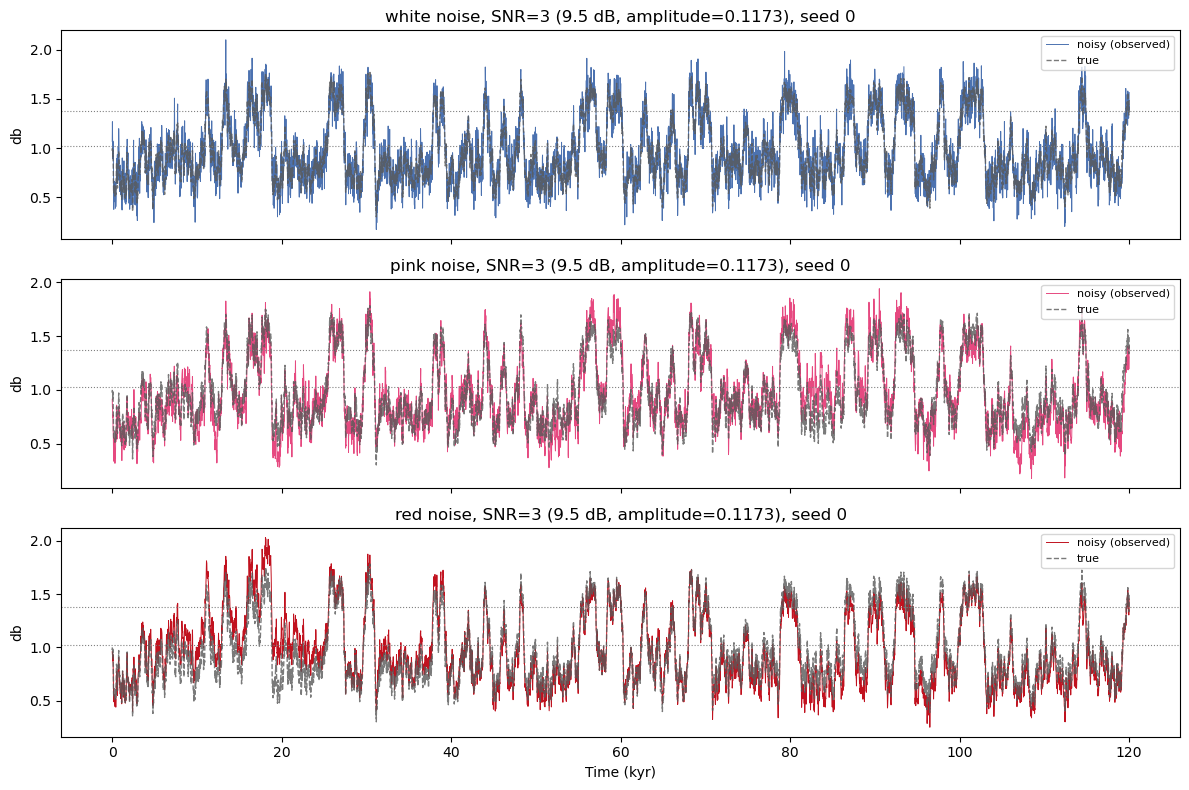

In [23]:
NOISE_PLOT_COLORS = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}  # noisy line matches its noise type
TRUE_COLOR = '#595959'   # ground truth

fig, axes = plt.subplots(len(NOISE_COLORS), 1, figsize=(12, 8), sharex=True)

for ax, color_name in zip(axes, NOISE_COLORS):
    d = grid_data[(color_name, 'snr3')]
    ax.plot(d['time'], d['db_noisy'][0], lw=0.7, color=NOISE_PLOT_COLORS[color_name], label='noisy (observed)')
    ax.plot(d['time'], d['db_true'][0], lw=1.0, color=TRUE_COLOR, ls='--', alpha=0.8, label='true')
    ax.axhline(_check_model.stadial_threshold, color='gray', ls=':', lw=0.8)
    ax.axhline(_check_model.interstadial_threshold, color='gray', ls=':',lw=0.8)
    ax.set_ylabel('db')
    ax.set_title(f"{color_name} noise, SNR=3 (9.5 dB, amplitude={NOISE_LEVELS['snr3']}), seed 0")
    ax.legend(fontsize=8, loc='upper right')

axes[-1].set_xlabel('Time (kyr)')
plt.tight_layout()
plt.show()

---
## Section 5 — Save Datasets for Later Ammonyte Analysis

One `.npz` per (color, level) condition (9 files), each containing the shared time axis plus `(n_seeds, n_time)` stacked arrays for `db_true`, `db_noisy`, `state_true`, `state_observed`. Transition times aren't stored directly — they can be recomputed on demand from the state arrays with `transition_times_from_states`. A manifest CSV and a config JSON (mirroring `best_config.json`'s pattern from scenario 1) are saved alongside for traceability.

In [24]:
for (color_name, level_name), d in grid_data.items():
    np.savez(
        f"{OUT_DIR}/noise_{color_name}_{level_name}.npz",
        time=d['time'],
        db_true=d['db_true'],
        db_noisy=d['db_noisy'],
        state_true=d['state_true'],
        state_observed=d['state_observed'],
        seeds=np.arange(N_SEEDS),
    )

summary_df.to_csv(f"{OUT_DIR}/noise_grid_manifest.csv", index=False)

with open(f"{OUT_DIR}/noise_grid_config.json", "w") as f:
    json.dump(dict(
        sigma=SIGMA, gamma=GAMMA, alpha=ALPHA,
        t_span=T_SPAN, dt=DT, y0=Y0,
        noise_colors=NOISE_COLORS, noise_levels=NOISE_LEVELS, n_seeds=N_SEEDS,
    ), f, indent=2)

print(f"Saved {len(grid_data)} condition files + manifest + config to {OUT_DIR}")

Saved 9 condition files + manifest + config to /Users/maryamniati/Documents/Syntheticdata/noise_sensitivity_data


---
## Section 6 — Interpreting the Saved Results

Reloads everything from the Section 5 output files only (`config.json`, `manifest.csv`, the 9 `.npz` files) — no dependency on in-memory variables, so this works standalone from disk.

Transition counts are recomputed from `state_true`/`state_observed` (`1` = stadial/cold, `0` = interstadial/warm) as a cross-check against `manifest_df`, then aggregated to mean ± std across the 20 seeds per (color, level) condition.

In [25]:
OUT_DIR = "/Users/maryamniati/Documents/Syntheticdata/noise_sensitivity_data"

# --- Load saved artifacts from disk ---
with open(f"{OUT_DIR}/noise_grid_config.json") as f:
    config = json.load(f)

manifest_df = pd.read_csv(f"{OUT_DIR}/noise_grid_manifest.csv")
all_npz_files = sorted(glob.glob(f"{OUT_DIR}/noise_*.npz"))

# OUT_DIR can accumulate stale files from earlier naming schemes (e.g. an old
# low/medium/high scheme, before the current SNR-based levels). Keep only files
# whose level matches a key in the current config, so leftovers are skipped
# instead of raising a KeyError.
npz_files, skipped_files = [], []
for f in all_npz_files:
    level_name = os.path.basename(f).replace("noise_", "").replace(".npz", "").split("_")[-1]
    (npz_files if level_name in config['noise_levels'] else skipped_files).append(f)

print(f"Config: {config}")
print(f"{len(npz_files)} files: {[os.path.basename(f) for f in npz_files]}")
if skipped_files:
    print(f"Skipped {len(skipped_files)} stale file(s) not in current config: "
          f"{[os.path.basename(f) for f in skipped_files]}")


# --- Recompute transition counts directly from each file's state arrays ---
# (independent check against manifest_df, using only the saved .npz content)
records = []

for f in npz_files:
    color_name, level_name = os.path.basename(f).replace("noise_", "").replace(".npz", "").split("_")
    amplitude = config['noise_levels'][level_name]

    d = np.load(f)
    n_true = np.sum(np.diff(d['state_true'], axis=1) != 0, axis=1)
    n_obs = np.sum(np.diff(d['state_observed'], axis=1) != 0, axis=1)

    for seed_idx, (nt, no) in enumerate(zip(n_true, n_obs)):
        records.append(dict(
            color=color_name, level=level_name, amplitude=amplitude,
            seed=seed_idx, n_true=nt, n_observed=no,
        ))

results_df = pd.DataFrame(records)


# --- Aggregate: mean + std across the 20 seeds, per (color, level) ---
agg = (
    results_df
    .groupby(['color', 'level', 'amplitude'])
    .agg(n_true_mean=('n_true', 'mean'),
         n_observed_mean=('n_observed', 'mean'),
         n_observed_std=('n_observed', 'std'))
    .reset_index()
    .sort_values(['color', 'amplitude'])
)

agg

Config: {'sigma': 0.5, 'gamma': 1.5, 'alpha': -0.5, 't_span': [0, 120], 'dt': 0.02, 'y0': [1.0, 0.0], 'noise_colors': {'white': 0.0, 'pink': 1.0, 'red': 2.0}, 'noise_levels': {'snr4': 0.088, 'snr3': 0.1173, 'snr2': 0.176}, 'n_seeds': 20}
9 files: ['noise_pink_snr2.npz', 'noise_pink_snr3.npz', 'noise_pink_snr4.npz', 'noise_red_snr2.npz', 'noise_red_snr3.npz', 'noise_red_snr4.npz', 'noise_white_snr2.npz', 'noise_white_snr3.npz', 'noise_white_snr4.npz']
Skipped 9 stale file(s) not in current config: ['noise_pink_high.npz', 'noise_pink_low.npz', 'noise_pink_medium.npz', 'noise_red_high.npz', 'noise_red_low.npz', 'noise_red_medium.npz', 'noise_white_high.npz', 'noise_white_low.npz', 'noise_white_medium.npz']


,color,level,amplitude,n_true_mean,n_observed_mean,n_observed_std
2,pink,snr4,0.0880,44.85,48.90,6.007890
1,pink,snr3,0.1173,44.85,56.15,7.321741
0,pink,snr2,0.1760,44.85,76.40,9.991575
5,red,snr4,0.0880,44.85,45.35,5.050013
4,red,snr3,0.1173,44.85,46.75,5.320022
3,red,snr2,0.1760,44.85,48.95,8.599113
8,white,snr4,0.0880,44.85,58.50,8.133750
7,white,snr3,0.1173,44.85,80.80,10.699729
6,white,snr2,0.1760,44.85,177.55,21.492900


--- 
## Section 7 — Visualizing Detection Degradation

Plots `agg`: mean observed transitions vs. amplitude, one line per noise color, error bars = std across seeds, dashed line = true count for reference.

Expect the rise above the dashed line to be steepest for `white` and flattest for `red`, with `pink` in between. Small error bars = consistent effect across seeds; large = noisy/variable.

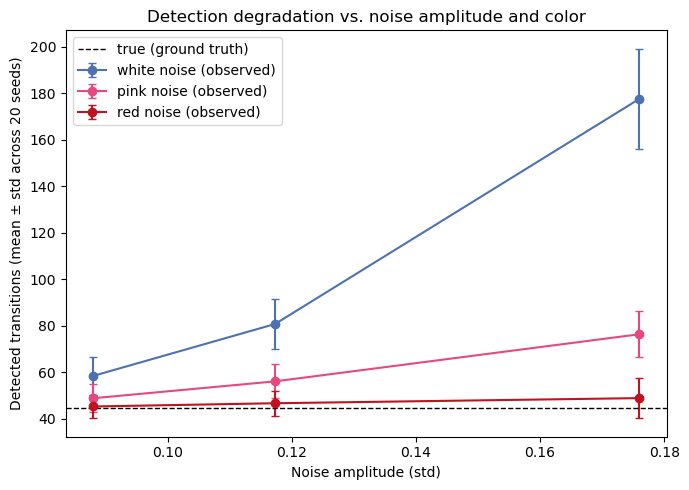

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))
for color_name, plot_color in NOISE_PLOT_COLORS.items():
    sub = agg[agg['color'] == color_name].sort_values('amplitude')
    ax.errorbar(sub['amplitude'], sub['n_observed_mean'], yerr=sub['n_observed_std'],
                marker='o', color=plot_color, label=f'{color_name} noise (observed)', capsize=3)

ax.axhline(agg['n_true_mean'].iloc[0], color='black', ls='--', lw=1, label='true (ground truth)')
ax.set_xlabel('Noise amplitude (std)')
ax.set_ylabel('Detected transitions (mean ± std across 20 seeds)')
ax.set_title('Detection degradation vs. noise amplitude and color')
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NPZ_PATH = "noise_sensitivity_data/noise_pink_snr2.npz"   # change color/level to inspect a different condition

d = np.load(NPZ_PATH)                                                    
# --- 1. What's inside the file, and what shape/type is each array ---   print(f"File: {NPZ_PATH}\
print(f"File: {NPZ_PATH}\n")
print(f"{'array':<16} {'shape':<14} {'dtype'}")
for key in d.files:
    print(f"{key:<16} {str(d[key].shape):<14} {d[key].dtype}")

n_seeds, n_time = d['db_noisy'].shape
print(f"\n-> {n_seeds} seeds (rows), each a {n_time}-point time series over "
      f"{d['time'].min():.1f}-{d['time'].max():.1f} kyr")

rows = []
for s in range(n_seeds):
    true_trans = transition_times_from_states(d['time'], d['state_true'][s])
    obs_trans = transition_times_from_states(d['time'], d['state_observed'][s])
    rows.append({
        'seed': int(d['seeds'][s]),
        'n_true_transitions': len(true_trans),
        'n_observed_transitions': len(obs_trans),
        'db_noisy_mean': d['db_noisy'][s].mean(),
        'db_noisy_std': d['db_noisy'][s].std(),
    })

seed_table = pd.DataFrame(rows)
print("\nPer-seed summary table:")
print(seed_table.to_string(index=False))


File: noise_sensitivity_data/noise_pink_snr2.npz

array            shape          dtype
time             (6001,)        float64
db_true          (20, 6001)     float64
db_noisy         (20, 6001)     float64
state_true       (20, 6001)     float64
state_observed   (20, 6001)     float64
seeds            (20,)          int64

-> 20 seeds (rows), each a 6001-point time series over 0.0-120.0 kyr

Per-seed summary table:
 seed  n_true_transitions  n_observed_transitions  db_noisy_mean  db_noisy_std
    0                  47                      79       0.969136      0.354789
    1                  44                      86       1.014828      0.352334
    2                  41                      80       0.960488      0.353310
    3                  42                      66       1.002257      0.370173
    4                  50                      72       1.010699      0.389926
    5                  47                      84       0.986762      0.363030
    6                  40 